# EquityAgent: Paired Evaluation Policy Comparison

**AAI 520 Final Project | Evaluation Lead**  
**NVIDIA recorded run: October 18, 2026**

This notebook replays **the same LLM rubric scores from one live integrated run** under two deterministic stopping and acceptance policies:

* **Original graph:** at least one revision, average score ≥ 4.0, up to three evaluations.
* **Enhanced graph:** same minimum revision and score threshold, plus accuracy ≥ 4, evidence ≥ 4, and no *recognized* numeric contradictions. The live policy reports unverified claims separately and does not block on unrecognized syntax.

**Methodological boundary:** Both branches use the same underlying LLM grader. The recorded revisions were produced with the enhanced optimizer feedback, so this is a **matched score policy replay**, not an independent original versus enhanced end to end experiment. The original pipeline's exact string numeric indicator and the new narrow numeric validator measure different things and must not be treated as directly comparable accuracy percentages.

The first source below is a transcription of terminal results, not a saved draft or findings snapshot. No API calls are made by this notebook.

In [1]:
from pathlib import Path
import importlib.util
import json
import pandas as pd
from IPython.display import display

root = Path.cwd()
if not (root / 'scripts' / 'compare_evaluator_policies.py').exists():
    root = root.parent
assert (root / 'scripts' / 'compare_evaluator_policies.py').exists(), 'Open the project root or notebooks directory as notebook working folder'
module_path = root / 'scripts' / 'compare_evaluator_policies.py'
spec = importlib.util.spec_from_file_location('paired_comparison', module_path)
comparison = importlib.util.module_from_spec(spec)
spec.loader.exec_module(comparison)
source_file = root / 'data' / 'evaluation' / 'nvda_oct18_logged.json'
source = json.loads(source_file.read_text(encoding='utf-8'))
result = comparison.compare_history(source['history'])
print('Stock:', source['ticker'])
print('Input:', source['source'])
print('Comparison type:', result['comparison_type'])

Stock: NVDA
Input: Transcribed from user's live integrated terminal output on 2026-10-18; no draft/findings snapshot was saved
Comparison type: matched_score_policy_replay_not_independent_agent_ab_test


## Actual recorded NVIDIA decisions

The first draft scored **4.0 / 5** overall, but **3 / 5 on accuracy**. It was not accepted by the new quality policy. The revised draft scored **4.8 / 5** overall and **5 / 5 on accuracy**. The existing graph also forces one revision, even if the first draft meets its average score threshold; hence both policy paths would finish at iteration 1 for these recorded scores.

In [2]:
df = pd.DataFrame(result['rows'])
show = df[['iteration', 'average', 'accuracy', 'evidence', 'original_action', 'enhanced_action', 'enhanced_failures', 'numeric_checked', 'numeric_unverified', 'numeric_contradicted']].copy()
show['enhanced_failures'] = show['enhanced_failures'].apply(lambda x: ', '.join(x) if x else 'none')
display(show)
print('Original policy stop iteration:', result['original_stop_iteration'])
print('Enhanced policy stop iteration:', result['enhanced_stop_iteration'])
print('Enhanced accepted selected iteration:', result['enhanced_selected_accepted_iteration'])

,iteration,average,accuracy,evidence,original_action,enhanced_action,enhanced_failures,numeric_checked,numeric_unverified,numeric_contradicted
0,0,4.0,3,4,revise,revise,accuracy_below_threshold,4,2,0
1,1,4.8,5,5,accept,accept,none,2,0,0


Original policy stop iteration: 1
Enhanced policy stop iteration: 1
Enhanced accepted selected iteration: 1


Matplotlib is building the font cache; this may take a moment.


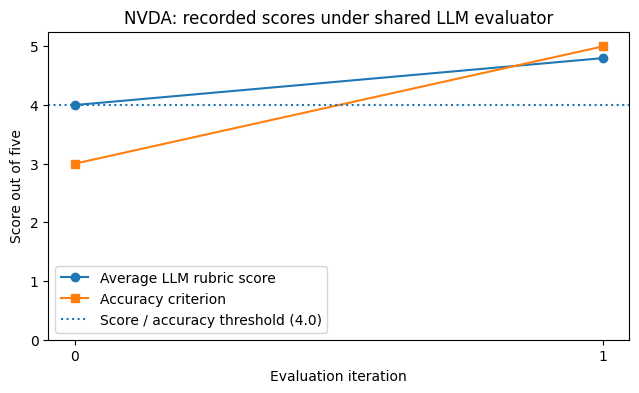

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(df['iteration'], df['average'], marker='o', label='Average LLM rubric score')
ax.plot(df['iteration'], df['accuracy'], marker='s', label='Accuracy criterion')
ax.axhline(4, linestyle=':', label='Score / accuracy threshold (4.0)')
ax.set(xticks=df['iteration'], ylim=(0, 5.25), xlabel='Evaluation iteration', ylabel='Score out of five', title='NVDA: recorded scores under shared LLM evaluator')
ax.legend()
plt.show()

## What the paired analysis supports

1. The enhanced policy explicitly identifies the first draft's insufficient accuracy, rather than relying only on the mean rubric score.
2. Both original and enhanced policies would revise at iteration 0 and accept at iteration 1 for these recorded evaluations. There is **no measured improvement in the selected revision on this case**.
3. The enhanced numeric checker recognized four claims initially and two claims in the revised draft; zero contradictions among two reviewed claims **does not validate all financial figures**. Different coverage and more compact wording may account for fewer matches.
4. The final 4.8 compared with 4.0 is an improvement across drafts **within the same enhanced run**, not a controlled difference between the two algorithms.
5. This is one NVDA trial. We have no frozen findings or original policy replay from JPM and XOM. Update the main results table only with separate documented runs.

## Optional: save a frozen paired dataset from one new live run

The terminal history used above did not save draft and specialist finding objects. To compare the original project's `unsupported_figures()` indicator with the enhanced numeric audit on the **identical drafts and findings**, run the following **in the VS Code terminal**, only after deciding to spend additional API credits:

```bash
python scripts/compare_evaluator_policies.py --live NVDA
```

That command executes **one enhanced LangGraph run**, freezes its specialist findings, evaluated drafts, rubric outputs, and both numeric diagnostics in a timestamped JSON file under `data/evaluation/`. Use `--input <file_path>` with the generated frozen file to replay policies again without additional API calls.

**Important:** This additional run still does not create a fair pair of independent original and enhanced optimizer loops. It isolates changes in the acceptance rules and applies numeric indicators to matched drafts. A separate end to end A/B study would need controlled inputs and carefully designed revision paths.

## Suggested report text (review and edit before submission)

> In a live NVDA integration trial, the combined agent completed its research, synthesis, evaluation, revision, and reflection workflow. The original LLM grader assigned the initial draft an overall score of 4.0 / 5 with accuracy 3 / 5. The enhanced evaluation policy marked this draft as below its accuracy threshold and guided a revised draft to 4.8 / 5, with accuracy 5 / 5. Replaying the original stopping policy over the same recorded scores showed that both policies would complete after revision 1, because the original system already requires at least one revision. The additional value demonstrated here is explicit quality criterion enforcement and a separate numerical audit, not a measured increase in final score compared to the original policy. Numerical checking was limited to two recognized final draft claims. Results reflect one NVDA trial and require broader evaluation before claims of general improvement.

**Disclosure:** Generative AI tools substantially assisted in writing this evaluation code, tests, and technical narrative. All reported results must be validated locally before submission.